In [103]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score
from sklearn.ensemble import RandomForestClassifier

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ashishsahani/hospital-admissions-data")

print("Path to dataset files:", path)

100%|██████████| 511k/511k [00:00<00:00, 111MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/ashishsahani/hospital-admissions-data/versions/1


In [3]:
import os

for file in os.listdir(path):
    print(file)

HDHI Pollution Data.csv
HDHI Admission data.csv
table_headings.csv
HDHI Mortality Data.csv


In [4]:
df1= pd.read_csv(os.path.join(path, "HDHI Mortality Data.csv"))

df2= pd.read_csv(os.path.join(path, "table_headings.csv"))

df3= pd.read_csv(os.path.join(path, "HDHI Admission data.csv"))

df4= pd.read_csv(os.path.join(path, "HDHI Pollution Data.csv"))

In [24]:
df3.head()

,SNO,MRD No.,D.O.A,D.O.D,AGE,GENDER,RURAL,TYPE OF ADMISSION-EMERGENCY/OPD,month year,DURATION OF STAY,...,CONGENITAL,UTI,NEURO CARDIOGENIC SYNCOPE,ORTHOSTATIC,INFECTIVE ENDOCARDITIS,DVT,CARDIOGENIC SHOCK,SHOCK,PULMONARY EMBOLISM,CHEST INFECTION
0,1,234735,4/1/2017,4/3/2017,81,M,R,E,Apr-17,3,...,0,0,0,0,0,0,0,0,0,0
1,2,234696,4/1/2017,4/5/2017,65,M,R,E,Apr-17,5,...,0,0,0,0,0,0,0,0,0,0
2,3,234882,4/1/2017,4/3/2017,53,M,U,E,Apr-17,3,...,0,0,0,0,0,0,0,0,0,0
3,4,234635,4/1/2017,4/8/2017,67,F,U,E,Apr-17,8,...,0,0,0,0,0,0,0,0,0,0
4,5,234486,4/1/2017,4/23/2017,60,F,U,E,Apr-17,23,...,0,0,0,0,0,0,0,0,0,0


In [10]:
print("Mortality:", df1.shape) #row, column
print("Table Headings:", df2.shape)
print("Admissions:", df3.shape)
print("Pollution Data:", df4.shape)

Mortality: (359, 6)
Table Headings: (16384, 2)
Admissions: (15757, 56)
Pollution Data: (737, 27)


In [11]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15757 entries, 0 to 15756
Data columns (total 56 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   SNO                              15757 non-null  int64 
 1   MRD No.                          15757 non-null  object
 2   D.O.A                            15757 non-null  object
 3   D.O.D                            15757 non-null  object
 4   AGE                              15757 non-null  int64 
 5   GENDER                           15757 non-null  object
 6   RURAL                            15757 non-null  object
 7   TYPE OF ADMISSION-EMERGENCY/OPD  15757 non-null  object
 8   month year                       15757 non-null  object
 9   DURATION OF STAY                 15757 non-null  int64 
 10  duration of intensive unit stay  15757 non-null  int64 
 11  OUTCOME                          15757 non-null  object
 12  SMOKING                         

In [12]:
df3.isnull().sum() #Find missing values

,0
SNO,0
MRD No.,0
D.O.A,0
D.O.D,0
AGE,0
GENDER,0
RURAL,0
TYPE OF ADMISSION-EMERGENCY/OPD,0
month year,0
DURATION OF STAY,0


*  BNP is often only measured when heart failure is suspected, so missing likely means "not tested" rather than truly unknown

*  Same logic for EF (ejection fraction) — not every patient gets an echo

Create a binary flag column then impute with median (safer than mean since glucose can be skewed by diabetic patients):

In [23]:
lab_cols = ['HB', 'TLC', 'PLATELETS', 'GLUCOSE', 'UREA', 'CREATININE', 'BNP', 'EF']
for col in lab_cols:
    df3[col] = pd.to_numeric(df3[col], errors='coerce')
    df3[col] = df3[col].fillna(df3[col].median())

df3[lab_cols].isnull().sum()

,0
HB,0
TLC,0
PLATELETS,0
GLUCOSE,0
UREA,0
CREATININE,0
BNP,0
EF,0


In [46]:
df3['OUTCOME'].value_counts()

,count
OUTCOME,
DISCHARGE,13756
EXPIRY,1105
DAMA,896


In [47]:
df3['OUTCOME_binary'] = (df3['OUTCOME'] == 'EXPIRY').astype(int)

df3['OUTCOME_binary']

,OUTCOME_binary
0,0
1,0
2,0
3,0
4,0
...,...
15752,0
15753,1
15754,0
15755,0


In [48]:
df3['OUTCOME_binary'].value_counts()

,count
OUTCOME_binary,
0,14652
1,1105


Missing values in laboratory variables (HB, TLC, Platelets, Glucose, Urea, Creatinine, BNP, and EF) were imputed using the median value of each variable to retain observations while minimizing the influence of outliers.

# EDA:

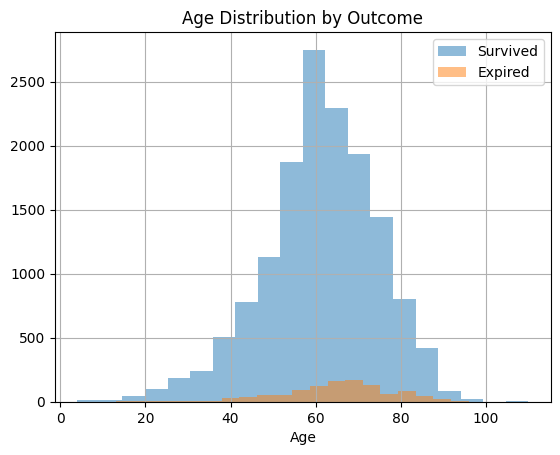

In [53]:
df3.groupby('OUTCOME_binary')['AGE'].hist(alpha=0.5, bins=20)
plt.legend(['Survived', 'Expired'])
plt.xlabel('Age')
plt.title('Age Distribution by Outcome')
plt.show()

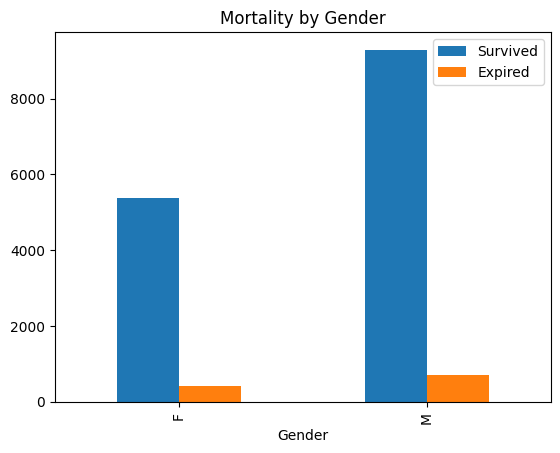

In [54]:
df3.groupby(['GENDER', 'OUTCOME_binary']).size().unstack().plot(kind='bar')
plt.legend(['Survived', 'Expired'])
plt.xlabel('Gender')
plt.title('Mortality by Gender')
plt.show()

More males in the dataset overall, and more male deaths in raw numbers. But raw counts are misleading here since there are way more male patients — need to look at mortality rate (% who died) not total count to draw real conclusions.

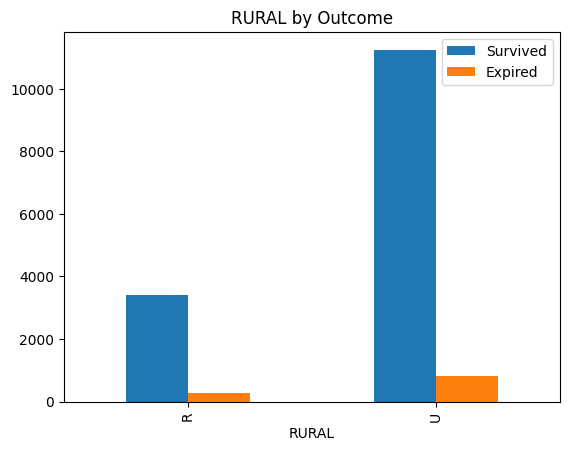

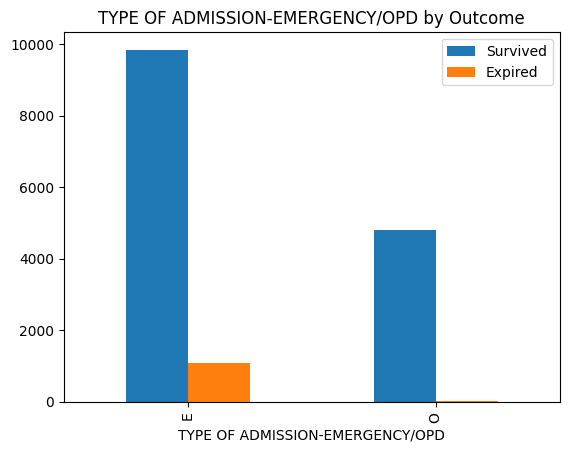

In [63]:
for col in ['RURAL', 'TYPE OF ADMISSION-EMERGENCY/OPD']:
    df3.groupby([col, 'OUTCOME_binary']).size().unstack().plot(kind='bar')
    plt.legend(['Survived', 'Expired'])
    plt.title(f'{col} by Outcome')
    plt.show()

*  Rural/Urban — urban patients dominate overall, but proportionally rural vs urban mortality looks similar
*  Admission type — emergency admissions have far more deaths than OPD, which makes sense — sicker patients come in via emergency

In [69]:
print(df3['SMOKING '].value_counts())
print(df3['ALCOHOL'].value_counts())

# Mortality rate by smoking status
smoking_mortality = df3.groupby('SMOKING ')['OUTCOME_binary'].mean() * 100
print(smoking_mortality)

# Mortality rate by alcohol status
alcohol_mortality = df3.groupby('ALCOHOL')['OUTCOME_binary'].mean() * 100
print(alcohol_mortality)

SMOKING 
0    14964
1      793
Name: count, dtype: int64
ALCOHOL
0    14736
1     1021
Name: count, dtype: int64
SMOKING 
0    7.237370
1    2.774275
Name: OUTCOME_binary, dtype: float64
ALCOHOL
0    7.410423
1    1.273262
Name: OUTCOME_binary, dtype: float64


*  Smokers had a lower observed mortality rate than non-smokers.
*  Alcohol users had a lower observed mortality rate than non-users.

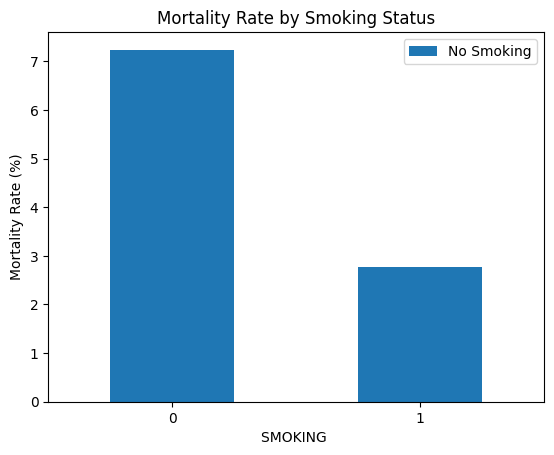

In [76]:
# Smoking
df3.groupby('SMOKING ')['OUTCOME_binary'].mean().mul(100).plot(kind='bar')
plt.ylabel('Mortality Rate (%)')
plt.legend(['No Smoking', 'Smoking'])
plt.title('Mortality Rate by Smoking Status')
plt.xticks(rotation=0)
plt.show()

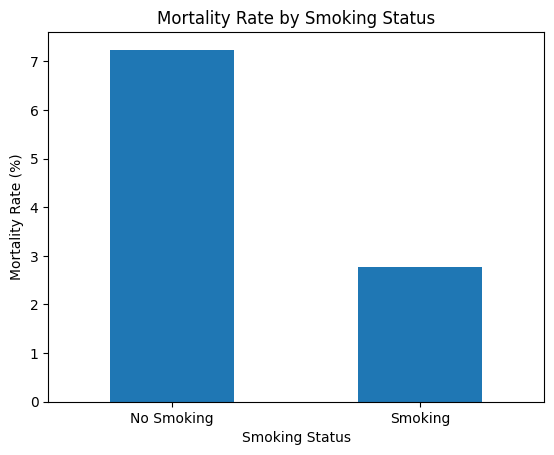

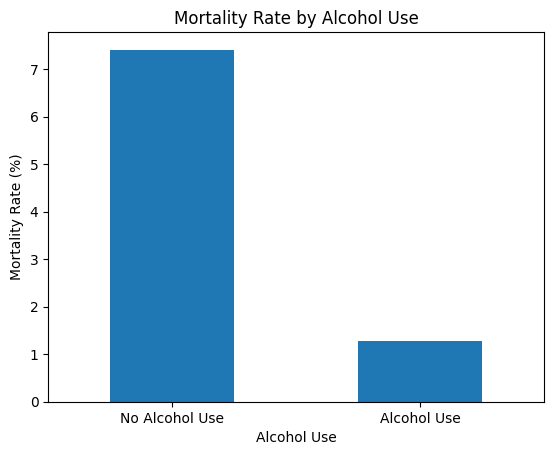

In [79]:
# Smoking
smoking_mortality = df3.groupby('SMOKING ')['OUTCOME_binary'].mean().mul(100)
smoking_mortality.index = ['No Smoking', 'Smoking']
smoking_mortality.plot(kind='bar')
plt.ylabel('Mortality Rate (%)')
plt.xlabel('Smoking Status')
plt.title('Mortality Rate by Smoking Status')
plt.xticks(rotation=0)
plt.show()

# Alcohol
alcohol_mortality = df3.groupby('ALCOHOL')['OUTCOME_binary'].mean().mul(100)
alcohol_mortality.index = ['No Alcohol Use', 'Alcohol Use']
alcohol_mortality.plot(kind='bar')
plt.ylabel('Mortality Rate (%)')
plt.xlabel('Alcohol Use')
plt.title('Mortality Rate by Alcohol Use')
plt.xticks(rotation=0)
plt.show()

Lifestyle variables are included as predictors. However, their interpretation is limited because behaviors may change after illness onset. Future models may need more detailed longitudinal lifestyle information (such as smoking history, pack-years, duration of alcohol use) rather than a simple yes/no variable.

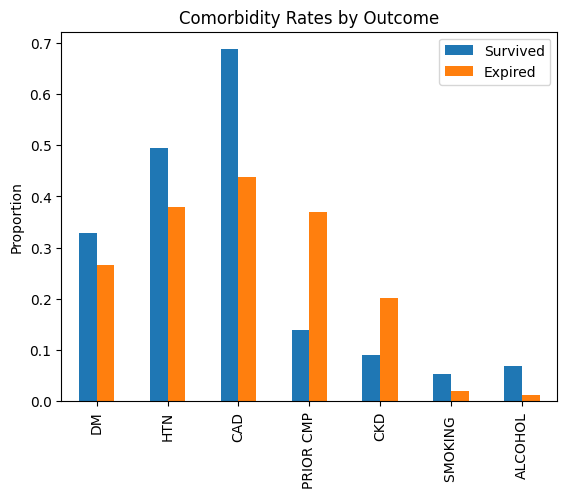

In [60]:
comorbidities = ['DM', 'HTN', 'CAD', 'PRIOR CMP', 'CKD', 'SMOKING ', 'ALCOHOL']
df3.groupby('OUTCOME_binary')[comorbidities].mean().T.plot(kind='bar')
plt.legend(['Survived', 'Expired'])
plt.ylabel('Proportion')
plt.title('Comorbidity Rates by Outcome')
plt.show()



*  PRIOR CMP and CKD — expired patients have much higher rates, biggest differentiators
*   CAD — survived patients actually have higher rates (likely because CAD patients are managed better/earlier)

*   SMOKING and ALCOHOL — surprisingly lower in expired group, counterintuitive but explainable (sicker patients may have already quit)





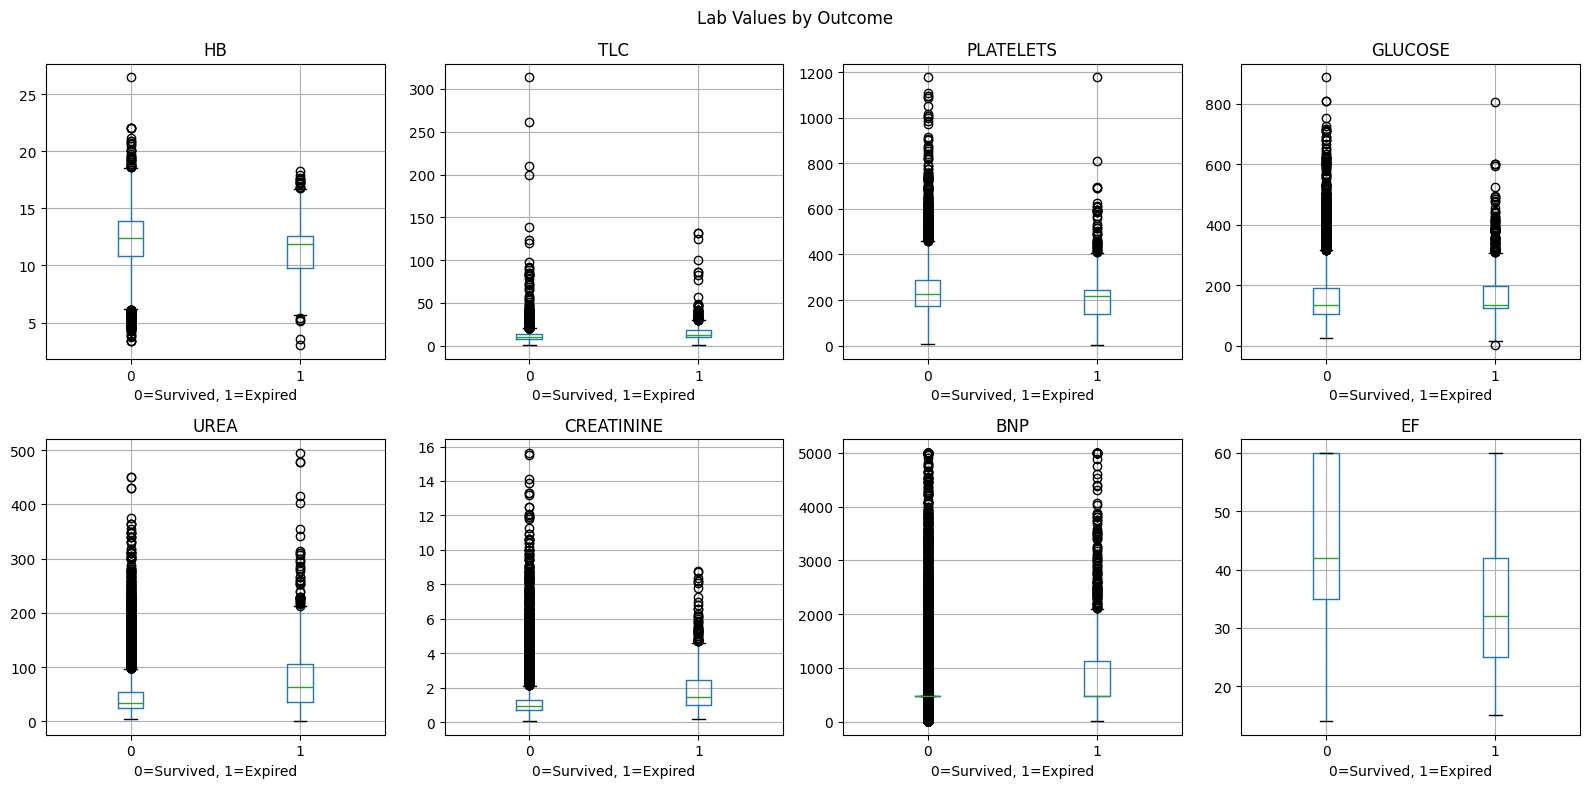

In [61]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(lab_cols):
    df3.boxplot(column=col, by='OUTCOME_binary', ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('0=Survived, 1=Expired')

plt.tight_layout()
plt.suptitle('Lab Values by Outcome')
plt.show()

*  UREA and CREATININE — notably higher in expired patients, kidney function is a strong signal
*  EF — lower in expired patients (lower ejection fraction = weaker heart)
*  HB — slightly lower in expired (anemia link)
*  BNP, TLC, PLATELETS, GLUCOSE — not much visible difference between groups

UREA, CREATININE, and EF will likely be important features in the model.

# Feature Selection:

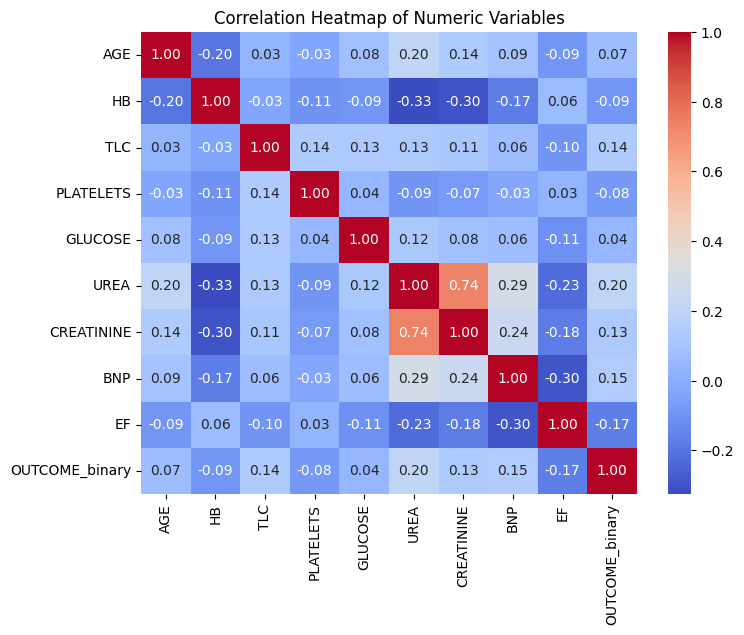

In [83]:
num_cols = ['AGE', 'HB', 'TLC', 'PLATELETS',
            'GLUCOSE', 'UREA', 'CREATININE',
            'BNP', 'EF', 'OUTCOME_binary']

plt.figure(figsize=(8,6))
sns.heatmap(df3[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numeric Variables')
plt.show()

Among numeric variables, urea, BNP, creatinine, and TLC showed positive associations with mortality, while EF showed a negative association, suggesting reduced cardiac function was linked with higher mortality risk.

In [86]:
cat_cols = ['DM', 'HTN', 'CAD', 'PRIOR CMP', 'CKD', 'SMOKING ', 'ALCOHOL',
            'GENDER', 'RURAL', 'TYPE OF ADMISSION-EMERGENCY/OPD']

for col in cat_cols:
    ct = pd.crosstab(df3[col], df3['OUTCOME_binary'])
    chi2, p, _, _ = chi2_contingency(ct)
    print(f"{col}: p={p:.4f}")

DM: p=0.0000
HTN: p=0.0000
CAD: p=0.0000
PRIOR CMP: p=0.0000
CKD: p=0.0000
SMOKING : p=0.0000
ALCOHOL: p=0.0000
GENDER: p=0.9522
RURAL: p=0.1519
TYPE OF ADMISSION-EMERGENCY/OPD: p=0.0000


Variables such as diabetes, hypertension, CAD, prior cardiomyopathy, CKD, smoking, alcohol use, and emergency admission type showed statistically significant associations with mortality. Gender and rural/urban location were not significantly associated with mortality in this dataset.

In [80]:
num_cols = ['AGE', 'HB', 'TLC', 'PLATELETS',
            'GLUCOSE', 'UREA', 'CREATININE',
            'BNP', 'EF']

df3[num_cols + ['OUTCOME_binary']].corr()['OUTCOME_binary'].sort_values()

,OUTCOME_binary
EF,-0.167099
HB,-0.090653
PLATELETS,-0.080649
GLUCOSE,0.039733
AGE,0.066890
CREATININE,0.133782
TLC,0.136505
BNP,0.145312
UREA,0.204570
OUTCOME_binary,1.000000


Among numerical variables, urea showed the strongest positive association with mortality, suggesting that impaired kidney function may be an important risk indicator. BNP, TLC, and creatinine also showed positive associations with mortality. EF demonstrated a negative relationship with mortality, indicating that lower cardiac function was associated with increased mortality risk. Age showed only a weak correlation, suggesting that other clinical factors may contribute more strongly to mortality prediction in this dataset.

In [81]:
selected_features = [
    'EF',
    'UREA',
    'CREATININE',
    'BNP',
    'TLC',
    'DM',
    'HTN',
    'CAD',
    'PRIOR CMP',
    'CKD',
    'SMOKING ',
    'ALCOHOL',
    'TYPE OF ADMISSION-EMERGENCY/OPD'
]

Based on correlation analysis and chi-square tests, 13 features were selected for model development, excluding:
* GENDER (p=0.952)
* RURAL (p=0.152)
* GLUCOSE (almost no correlation)
* PLATELETS (very weak)

# Building Model

In [87]:
#Create X and y
selected_features = [
    'EF',
    'UREA',
    'CREATININE',
    'BNP',
    'TLC',
    'DM',
    'HTN',
    'CAD',
    'PRIOR CMP',
    'CKD',
    'SMOKING ',
    'ALCOHOL',
    'TYPE OF ADMISSION-EMERGENCY/OPD'
]

X = df3[selected_features]
y = df3['OUTCOME_binary']

In [95]:
#Convert admission type to numbers
df3['TYPE OF ADMISSION-EMERGENCY/OPD'] = df3['TYPE OF ADMISSION-EMERGENCY/OPD'].map({
    'E': 1,
    'O': 0
})

In [96]:
df3['TYPE OF ADMISSION-EMERGENCY/OPD'].value_counts()

,count
TYPE OF ADMISSION-EMERGENCY/OPD,
1,10924
0,4833


In [100]:
# Split data
X = df3[selected_features]
y = df3['OUTCOME_binary']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Logistic Regression
log_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

log_model.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [102]:
#Evaluation
y_pred = log_model.predict(X_test)
y_prob = log_model.predict_proba(X_test)[:,1]

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("AUC:", roc_auc_score(y_test, y_prob))

[[2084  847]
 [  48  173]]
              precision    recall  f1-score   support

           0       0.98      0.71      0.82      2931
           1       0.17      0.78      0.28       221

    accuracy                           0.72      3152
   macro avg       0.57      0.75      0.55      3152
weighted avg       0.92      0.72      0.79      3152

AUC: 0.8246085301296331


Recall = 0.78
* The model correctly identified 78% of patients who eventually expired.
Precision = 0.17
* Among patients predicted as high mortality risk, only 17% actually expired.
AUC = 0.825
* The logistic regression model demonstrated good discrimination ability, achieving an AUC of 0.825, indicating it can reasonably distinguish between patients with higher and lower mortality risk.

In [104]:
#Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [105]:
#Evaluation
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:,1]

print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
print("AUC:", roc_auc_score(y_test, y_prob_rf))

[[2910   21]
 [ 126   95]]
              precision    recall  f1-score   support

           0       0.96      0.99      0.98      2931
           1       0.82      0.43      0.56       221

    accuracy                           0.95      3152
   macro avg       0.89      0.71      0.77      3152
weighted avg       0.95      0.95      0.95      3152

AUC: 0.9610614263814337


* Excellent discrimination (AUC = 0.961)
* Much fewer false positives
High precision (82%)
* Misses more expired patients (recall drops to 43%)

When it predicts a patient is high risk, it is usually correct, but it misses more actual deaths.

# Interpretation

In [106]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=selected_features
).sort_values(ascending=False)

importance

,0
CREATININE,0.198513
EF,0.187473
UREA,0.184572
TLC,0.142755
TYPE OF ADMISSION-EMERGENCY/OPD,0.086742
BNP,0.077836
CAD,0.044463
PRIOR CMP,0.021134
HTN,0.017432
DM,0.014290


Strongest predictors were primarily clinical severity markers rather than lifestyle factors.